
BASE vs ENSEMBLE MODEL COMPARISON
-----------------------------------------------------------------------------------------------
                  Model  Accuracy  Precision  Recall  F1-Score  CV Acc (mean)  CV Acc (std)
    Logistic Regression    0.9722     0.9721  0.9719    0.9719         0.9711        0.0037
          Decision Tree    0.8250     0.8236  0.8242    0.8230         0.8547        0.0138
Decision Tree (depth=3)    0.4833     0.3912  0.4830    0.3991         0.4680        0.0172
                    KNN    0.9639     0.9646  0.9637    0.9634         0.9789        0.0063
            Naive Bayes    0.8111     0.8463  0.8103    0.8137         0.8453        0.0176
                    SVM    0.9750     0.9760  0.9748    0.9748         0.9839        0.0060
          Voting (Hard)    0.9639     0.9651  0.9636    0.9633         0.9844        0.0049
               Stacking    0.9833     0.9836  0.9832    0.9832         0.9866        0.0021
               AdaBoost    0.9444     0.9

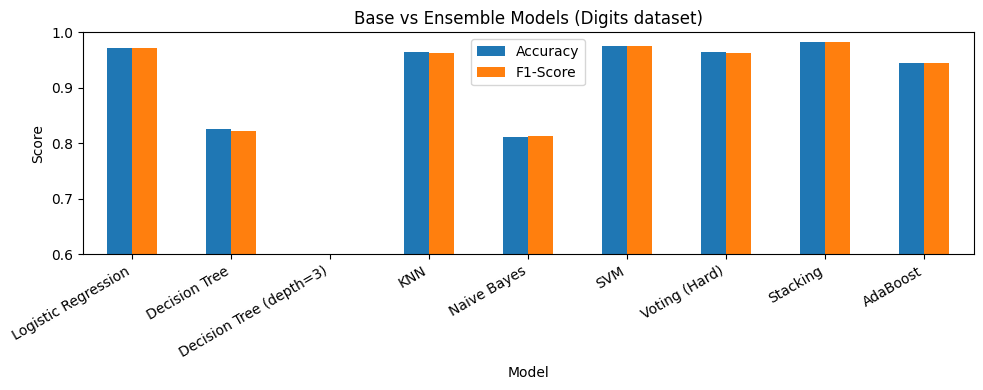

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load dataset (Digits: 1797 samples, 64 features, 10 classes)
data = load_digits()
X = data.data
y = data.target

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Base classifiers
def base_models():
    return [
        ("lr", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))),
        ("dt", DecisionTreeClassifier(random_state=42)),
        ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))),
        ("nb", GaussianNB()),
        ("svm", make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, random_state=42))),
    ]

base = dict(base_models())

models = {
    # Base models
    "Logistic Regression": base["lr"],
    "Decision Tree": base["dt"],
    "Decision Tree (depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42),  # AdaBoost weak learner
    "KNN": base["knn"],
    "Naive Bayes": base["nb"],
    "SVM": base["svm"],
    # Ensemble models
    "Voting (Hard)": VotingClassifier(estimators=base_models(), voting="hard"),
    "Stacking": StackingClassifier(
        estimators=base_models(),
        final_estimator=LogisticRegression(max_iter=2000, random_state=42),
        cv=5
    ),
    "AdaBoost": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3, random_state=42),
        n_estimators=100, learning_rate=0.5, random_state=42
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = []

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    cv = cross_val_score(model, X, y, cv=skf, scoring="accuracy")
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, average="macro"), 4),
        "F1-Score": round(f1_score(y_test, y_pred, average="macro"), 4),
        "CV Acc (mean)": round(cv.mean(), 4),
        "CV Acc (std)": round(cv.std(), 4)
    })

# Display comparison table
df = pd.DataFrame(results)
print("\nBASE vs ENSEMBLE MODEL COMPARISON")
print("-" * 95)
print(df.to_string(index=False))

# Display the best results
def best(metric):
    return ", ".join(df.loc[df[metric] == df[metric].max(), "Model"])

print("\nPERFORMANCE SUMMARY")
print("Highest Accuracy:", best("Accuracy"))
print("Highest F1-Score:", best("F1-Score"))
print("Highest CV Accuracy:", best("CV Acc (mean)"))
print("\nProgram executed successfully!")

# Bar chart for visual comparison
ax = df.set_index("Model")[["Accuracy", "F1-Score"]].plot(kind="bar", figsize=(10, 4))
ax.set_ylim(0.6, 1.0)
ax.set_ylabel("Score")
ax.set_title("Base vs Ensemble Models (Digits dataset)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("ensemble_comparison.png", dpi=150)
plt.show()